# 01 Explore ENSO data

Task 3 in `specs/tasks.md`. This notebook only looks at the data. It builds no models and changes no files.

Two files in `data/raw/enso/`:
- `oni.ascii.txt` from NOAA: the source of truth for ONI.
- `dataset_enso_2026.csv` from Kaggle: secondary source for RONI, Nino 3.4 anomaly, and SOI.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ENSO_DIR = Path("../data/raw/enso")
NOAA_ONI_PATH = ENSO_DIR / "oni.ascii.txt"
KAGGLE_PATH = ENSO_DIR / "dataset_enso_2026.csv"

## 1. NOAA ONI

Columns: SEAS, YR, TOTAL, ANOM. ANOM is the ONI value. Each season is a three-month average, so we give it the date of its centre month (DJF = January, ..., NDJ = December).

In [2]:
# Season code -> centre month number. DJF is centred on January, NDJ on December.
SEASON_TO_CENTRE_MONTH = {
    "DJF": 1, "JFM": 2, "FMA": 3, "MAM": 4, "AMJ": 5, "MJJ": 6,
    "JJA": 7, "JAS": 8, "ASO": 9, "SON": 10, "OND": 11, "NDJ": 12,
}

# The file is separated by runs of spaces.
noaa = pd.read_csv(NOAA_ONI_PATH, sep=r"\s+")
print("Columns:", list(noaa.columns))

noaa["month"] = noaa["SEAS"].map(SEASON_TO_CENTRE_MONTH)
print("Seasons that did not map:", noaa["month"].isna().sum())

noaa["date"] = pd.to_datetime({"year": noaa["YR"], "month": noaa["month"], "day": 1})
noaa = noaa.rename(columns={"ANOM": "oni"})[["date", "SEAS", "YR", "TOTAL", "oni"]]
noaa.head()

Columns: ['SEAS', 'YR', 'TOTAL', 'ANOM']
Seasons that did not map: 0


,date,SEAS,YR,TOTAL,oni
0,1950-01-01,DJF,1950,25.01,-1.32
1,1950-02-01,JFM,1950,25.36,-1.20
2,1950-03-01,FMA,1950,25.88,-1.12
3,1950-04-01,MAM,1950,26.24,-1.08
4,1950-05-01,AMJ,1950,26.35,-1.10


## 2. Kaggle ENSO file

Loader rules from `specs/layer1-forecast.md`: strip column names, drop `Unnamed: 0`, parse `Date` as M/D/YYYY, ignore Season columns, drop placeholder rows where RONI, Nino 3.4 anomaly and SOI are all empty.

In [3]:
kaggle_raw = pd.read_csv(KAGGLE_PATH)
kaggle_raw.columns = kaggle_raw.columns.str.strip()
kaggle_raw = kaggle_raw.drop(columns=["Unnamed: 0"])
print("All columns:", list(kaggle_raw.columns))

# The phase-intensity column name contains a literal replacement character, so find it by pattern.
phase_oni_col = next(
    c for c in kaggle_raw.columns if c.startswith("ENSO Phase") and c.endswith("(ONI-based)")
)
KEPT_COLUMNS = ["Date", "ONI", "RONI", "Nino 3.4 SST Anomaly", "SOI", phase_oni_col]
VALUE_COLUMNS = ["RONI", "Nino 3.4 SST Anomaly", "SOI"]

kaggle = kaggle_raw[KEPT_COLUMNS].copy()
kaggle["Date"] = pd.to_datetime(kaggle["Date"], format="%m/%d/%Y")

rows_before = len(kaggle)
placeholder = kaggle[VALUE_COLUMNS].isna().all(axis=1)
print("Placeholder rows dropped:", placeholder.sum(), "->", list(kaggle.loc[placeholder, "Date"].dt.strftime("%Y-%m")))
kaggle = kaggle[~placeholder].reset_index(drop=True)
kaggle.head()

All columns: ['Date', 'Year', 'Month', 'Global Temperature Anomaly', 'Nino 1+2 SST', 'Nino 1+2 SST Anomaly', 'Nino 3 SST', 'Nino 3 SST Anomaly', 'Nino 3.4 SST', 'Nino 3.4 SST Anomaly', 'Nino 4 SST', 'Nino 4 SST Anomaly', 'TNI', 'SOI', 'OLR', 'PNA', 'NOI', 'ENSO Precipitation Index', 'BEST', 'Season (2-Month)', 'MEI.ext', 'MEI.v2', 'Season (3-Month)', 'ONI', 'RONI', 'Season (12-Month)', 'ENSO Phase�Intensity (ONI-based)', 'ENSO Phase�Intensity (RONI-based)']
Placeholder rows dropped: 7 -> ['2026-06', '2026-07', '2026-08', '2026-09', '2026-10', '2026-11', '2026-12']


,Date,ONI,RONI,Nino 3.4 SST Anomaly,SOI,ENSO Phase�Intensity (ONI-based)
0,1950-01-01,-1.53,-1.58,-1.99,NaN,N
1,1950-02-01,-1.34,-1.26,-1.69,NaN,N
2,1950-03-01,-1.16,-0.96,-1.42,NaN,N
3,1950-04-01,-1.18,-1.10,-1.54,NaN,N
4,1950-05-01,-1.07,-1.20,-1.75,NaN,N


## 3. Date range, row counts, missing values

In [4]:
def summarise(name, df, date_col):
    print(f"--- {name} ---")
    print("First date:", df[date_col].min().strftime("%Y-%m"))
    print("Last date: ", df[date_col].max().strftime("%Y-%m"))
    print("Rows:      ", len(df))
    # A monthly series should have one row per month with no gaps.
    expected = pd.date_range(df[date_col].min(), df[date_col].max(), freq="MS")
    print("Missing months in range:", len(expected.difference(df[date_col])))
    print("Duplicate dates:", df[date_col].duplicated().sum())
    print("Missing values per column:")
    print(df.isna().sum().to_string())
    print()

summarise("NOAA oni.ascii.txt", noaa, "date")
print("Kaggle rows before dropping placeholders:", rows_before)
summarise("Kaggle (kept columns)", kaggle, "Date")

--- NOAA oni.ascii.txt ---
First date: 1950-01
Last date:  2026-09
Rows:       921
Missing months in range: 0
Duplicate dates: 0
Missing values per column:
date     0
SEAS     0
YR       0
TOTAL    0
oni      0

Kaggle rows before dropping placeholders: 924
--- Kaggle (kept columns) ---
First date: 1950-01
Last date:  2026-05
Rows:       917
Missing months in range: 0
Duplicate dates: 0
Missing values per column:
Date                                 0
ONI                                  1
RONI                                 1
Nino 3.4 SST Anomaly                 0
SOI                                 12
ENSO Phase�Intensity (ONI-based)     5



NOAA sometimes uses sentinel values such as -99.9 for missing data instead of blanks. Check the value ranges so a sentinel would show up.

In [5]:
print(noaa[["TOTAL", "oni"]].describe().round(2))
print()
print(kaggle[["ONI", "RONI", "Nino 3.4 SST Anomaly", "SOI"]].describe().round(2))

        TOTAL     oni
count  921.00  921.00
mean    26.94    0.02
std      0.91    0.79
min     24.39   -2.04
25%     26.31   -0.51
50%     26.98   -0.04
75%     27.57    0.50
max     29.23    2.59

          ONI    RONI  Nino 3.4 SST Anomaly     SOI
count  916.00  916.00                917.00  905.00
mean     0.03    0.02                 -0.18    0.26
std      0.83    0.87                  0.87    1.55
min     -2.03   -2.15                 -2.45   -6.00
25%     -0.55   -0.55                 -0.78   -0.70
50%     -0.04   -0.04                 -0.25    0.30
75%      0.54    0.58                  0.35    1.30
max      2.75    2.69                  2.72    4.80


In [6]:
# Where are the Kaggle gaps? Show the first and last date that has a value, per column.
for col in ["ONI", "RONI", "Nino 3.4 SST Anomaly", "SOI", phase_oni_col]:
    has_value = kaggle.loc[kaggle[col].notna(), "Date"]
    print(f"{col:40s} {has_value.min():%Y-%m} to {has_value.max():%Y-%m}, missing {kaggle[col].isna().sum()}")

ONI                                      1950-01 to 2026-04, missing 1
RONI                                     1950-01 to 2026-04, missing 1
Nino 3.4 SST Anomaly                     1950-01 to 2026-05, missing 0
SOI                                      1951-01 to 2026-05, missing 12
ENSO Phase�Intensity (ONI-based)         1950-01 to 2025-12, missing 5


## 4. ONI over time

Red line +0.5 (El Nino threshold), blue line -0.5 (La Nina threshold). The marked events show the peak ONI found inside a rough window for each event. These windows are only for the chart. The real event start and end come from the labels in task 5.

1982-83: peak ONI 2.14 in 1983-01
1997-98: peak ONI 2.37 in 1997-12
2015-16: peak ONI 2.59 in 2015-12
2023-24: peak ONI 1.99 in 2023-12
2026 (ongoing): peak ONI 2.46 in 2026-09


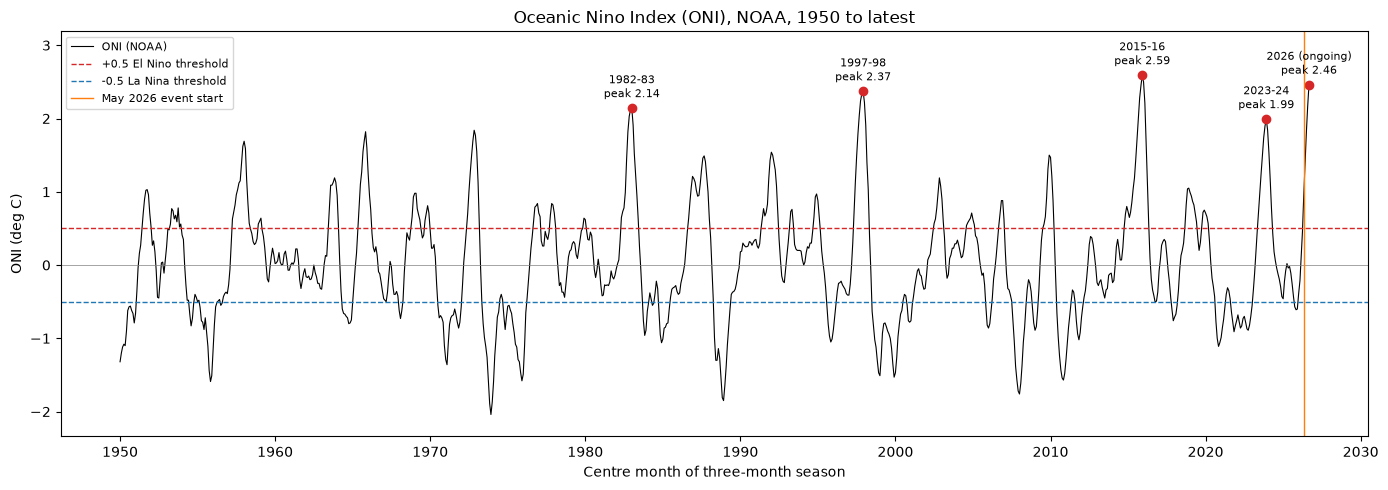

In [7]:
# Rough search windows, only to place the markers on the chart.
EVENT_WINDOWS = {
    "1982-83": ("1982-01", "1983-12"),
    "1997-98": ("1997-01", "1998-12"),
    "2015-16": ("2015-01", "2016-12"),
    "2023-24": ("2023-01", "2024-12"),
    "2026 (ongoing)": ("2026-05", "2026-12"),
}

oni_series = noaa.set_index("date")["oni"]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(oni_series.index, oni_series.values, color="black", linewidth=0.8, label="ONI (NOAA)")
ax.axhline(0.5, color="tab:red", linestyle="--", linewidth=1, label="+0.5 El Nino threshold")
ax.axhline(-0.5, color="tab:blue", linestyle="--", linewidth=1, label="-0.5 La Nina threshold")
ax.axhline(0, color="grey", linewidth=0.5)

for name, (start, end) in EVENT_WINDOWS.items():
    window = oni_series[start:end]
    peak_date = window.idxmax()
    peak_value = window.max()
    ax.plot(peak_date, peak_value, "o", color="tab:red")
    ax.annotate(f"{name}\npeak {peak_value:.2f}", (peak_date, peak_value),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
    print(f"{name}: peak ONI {peak_value:.2f} in {peak_date:%Y-%m}")

# The 2026 event start (May 2026) as given in the specs.
ax.axvline(pd.Timestamp("2026-05-01"), color="tab:orange", linewidth=1, label="May 2026 event start")

ax.set_title("Oceanic Nino Index (ONI), NOAA, 1950 to latest")
ax.set_xlabel("Centre month of three-month season")
ax.set_ylabel("ONI (deg C)")
ax.set_ylim(oni_series.min() - 0.3, oni_series.max() + 0.6)
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
# The newest months, to see the 2026 event so far.
noaa.tail(10)

,date,SEAS,YR,TOTAL,oni
911,2025-12-01,NDJ,2025,25.96,-0.60
912,2026-01-01,DJF,2026,26.15,-0.39
913,2026-02-01,JFM,2026,26.57,-0.21
914,2026-03-01,FMA,2026,27.34,0.11
915,2026-04-01,MAM,2026,28.09,0.46
916,2026-05-01,AMJ,2026,28.74,0.95
917,2026-06-01,MJJ,2026,29.02,1.39
918,2026-07-01,JJA,2026,29.09,1.80
919,2026-08-01,JAS,2026,29.12,2.16
920,2026-09-01,ASO,2026,29.23,2.46


## 5. Kaggle SOI vs NOAA soi.txt

`soi.txt` has two blocks: **ANOMALY** (top) and **STANDARDIZED DATA** (bottom). The Kaggle SOI matches the ANOMALY block, so only that block is read.

The file is fixed-width and numbers can touch (`-1.7-999.9`), so it is read with fixed column widths, not by splitting on spaces. `-999.9` means missing.

In [9]:
MONTHS = ["JAN", "FEB", "MAR", "APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"]
NOAA_SOI_PATH = ENSO_DIR / "soi.txt"

# ANOMALY block: 4 header lines, then one row per year (1951 to 2030).
# Widths: 4 characters for the year, then 6 per month.
soi_grid = pd.read_fwf(
    NOAA_SOI_PATH, widths=[4] + [6] * 12, names=["YEAR", *MONTHS], skiprows=4, nrows=80
)

# Year-by-month grid -> one row per month.
noaa_soi = soi_grid.melt(id_vars="YEAR", var_name="month_name", value_name="soi_noaa")
month_number = noaa_soi["month_name"].map({name: i + 1 for i, name in enumerate(MONTHS)})
noaa_soi["date"] = pd.to_datetime({"year": noaa_soi["YEAR"], "month": month_number, "day": 1})
noaa_soi["soi_noaa"] = noaa_soi["soi_noaa"].where(noaa_soi["soi_noaa"] > -999)  # -999.9 -> NaN
noaa_soi = noaa_soi.dropna(subset=["soi_noaa"]).sort_values("date")[["date", "soi_noaa"]]

summarise("NOAA soi.txt (ANOMALY block)", noaa_soi, "date")

--- NOAA soi.txt (ANOMALY block) ---
First date: 1951-01
Last date:  2026-10
Rows:       910
Missing months in range: 0
Duplicate dates: 0
Missing values per column:
date        0
soi_noaa    0



In [10]:
soi_both = kaggle[["Date", "SOI"]].rename(columns={"Date": "date", "SOI": "soi_kaggle"}).merge(
    noaa_soi, on="date", how="outer"
)
overlap = soi_both.dropna()
difference = (overlap["soi_kaggle"] - overlap["soi_noaa"]).abs()

print("Months in both files:      ", len(overlap))
print("Months that match exactly: ", (difference < 1e-9).sum())
print("Mean absolute difference:  ", round(difference.mean(), 3))
print("Largest difference:        ", round(difference.max(), 3))

only_noaa = soi_both["soi_kaggle"].isna() & soi_both["soi_noaa"].notna()
only_kaggle = soi_both["soi_kaggle"].notna() & soi_both["soi_noaa"].isna()
print("Months only in NOAA:  ", list(soi_both.loc[only_noaa, "date"].dt.strftime("%Y-%m")))
print("Months only in Kaggle:", list(soi_both.loc[only_kaggle, "date"].dt.strftime("%Y-%m")))

Months in both files:       905
Months that match exactly:  905
Mean absolute difference:   0.0
Largest difference:         0.0
Months only in NOAA:   ['2026-06', '2026-07', '2026-08', '2026-09', '2026-10']
Months only in Kaggle: []
